In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Airbnb dataset
df = pd.read_csv('/content/AB_NYC_2019_clean.csv')

# Display the first five rows
display(df.head())

# Check dataset size
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,has_reviews,log_price
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365,1,5.003946
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355,1,5.416100
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,0.00,1,365,0,5.010635
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194,1,4.488636
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0,1,4.382027


Dataset shape: (48396, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48396 entries, 0 to 48395
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48396 non-null  int64  
 1   name                            48381 non-null  object 
 2   host_id                         48396 non-null  int64  
 3   host_name                       48375 non-null  object 
 4   neighbourhood_group             48396 non-null  object 
 5   neighbourhood                   48396 non-null  object 
 6   latitude                        48396 non-null  float64
 7   longitude                       48396 non-null  float64
 8   room_type                       48396 non-null  object 
 9   price                           48396 non-null  int64  
 10  minimum_nights                  48396 non-null  int64  
 11  number_of_reviews               48396 non-null  int64  
 12  last_

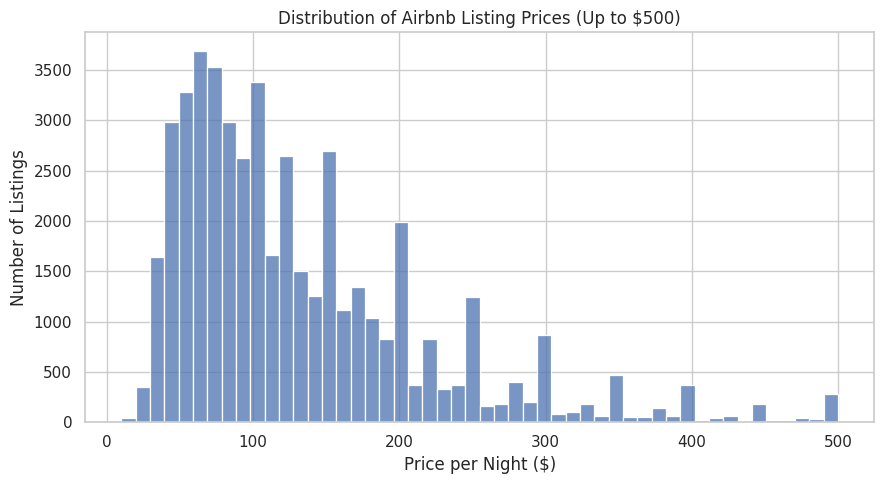

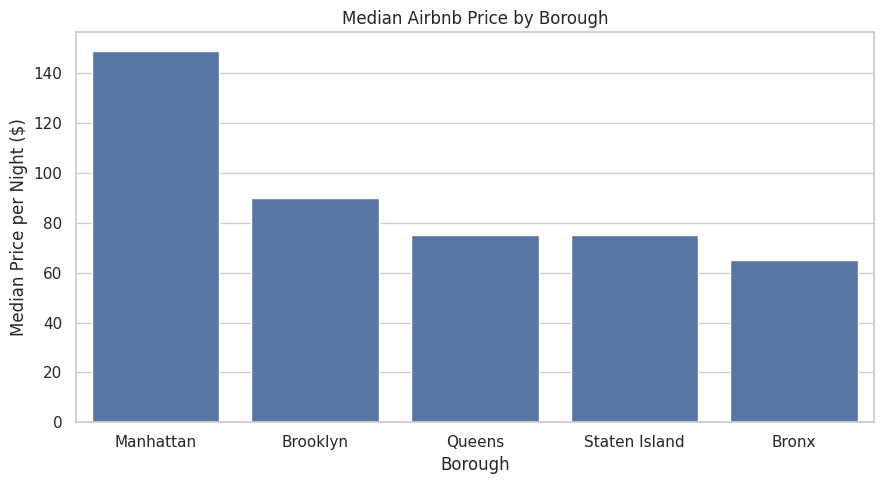

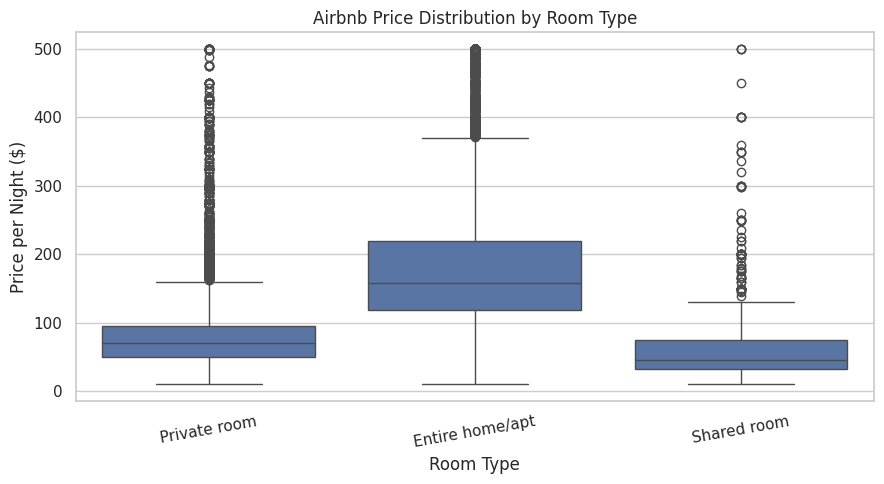

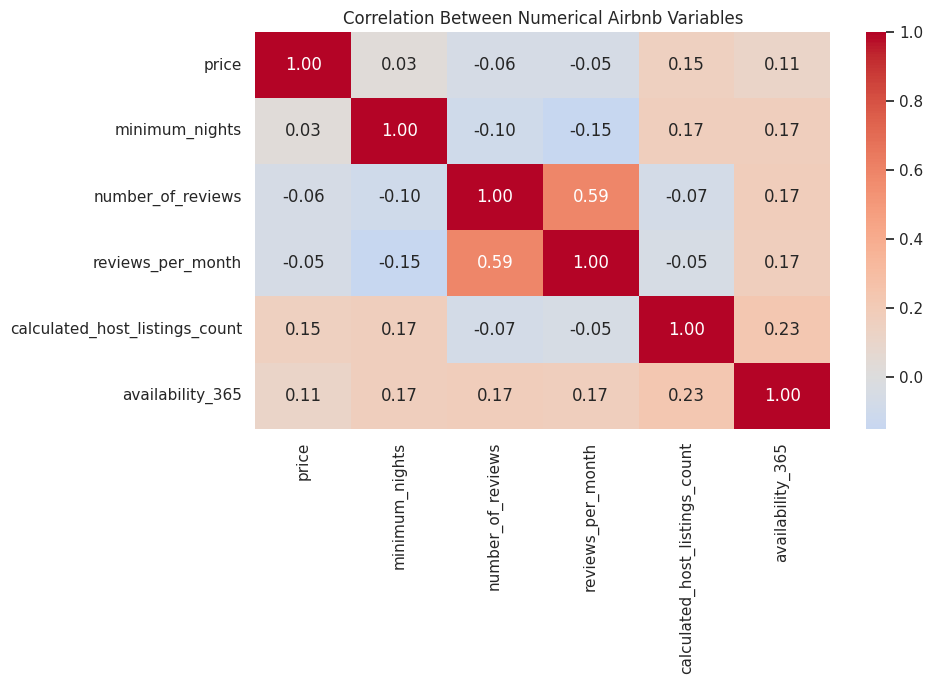

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Distribution of listing prices
plt.figure(figsize=(9, 5))
sns.histplot(df[df["price"] <= 500]["price"], bins=50)
plt.title("Distribution of Airbnb Listing Prices (Up to $500)")
plt.xlabel("Price per Night ($)")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

# 2. Median price by borough
borough_order = (
    df.groupby("neighbourhood_group")["price"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=df, x="neighbourhood_group", y="price",
    order=borough_order, estimator=np.median,
    errorbar=None
)
plt.title("Median Airbnb Price by Borough")
plt.xlabel("Borough")
plt.ylabel("Median Price per Night ($)")
plt.tight_layout()
plt.show()

# 3. Price by room type
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df[df["price"] <= 500],
    x="room_type", y="price"
)
plt.title("Airbnb Price Distribution by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Price per Night ($)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# 4. Correlation heatmap
numeric_cols = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

plt.figure(figsize=(10, 7))
correlation = df[numeric_cols].corr()
sns.heatmap(
    correlation, annot=True, fmt=".2f",
    cmap="coolwarm", center=0
)
plt.title("Correlation Between Numerical Airbnb Variables")
plt.tight_layout()
plt.show()


In [13]:
# Price statistics
print("PRICE SUMMARY")
print(df["price"].describe().round(2))

# Median price by borough and room type
print("\nMEDIAN PRICE BY BOROUGH")
print(df.groupby("neighbourhood_group")["price"].median().sort_values(ascending=False))

print("\nMEDIAN PRICE BY ROOM TYPE")
print(df.groupby("room_type")["price"].median().sort_values(ascending=False))

# Review statistics
print("\nREVIEW SUMMARY")
print(df[["number_of_reviews", "reviews_per_month"]].describe().round(2))

# Listings with no reviews
print("\nLISTINGS WITH ZERO REVIEWS")
print((df["number_of_reviews"] == 0).sum())

# Unique values in categorical variables
print("\nROOM TYPE COUNTS")
print(df["room_type"].value_counts())

print("\nBOROUGH COUNTS")
print(df["neighbourhood_group"].value_counts())


PRICE SUMMARY
count    48396.00
mean       137.58
std        103.78
min         10.00
25%         69.00
50%        105.00
75%        175.00
max        799.00
Name: price, dtype: float64

MEDIAN PRICE BY BOROUGH
neighbourhood_group
Manhattan        149.0
Brooklyn          90.0
Queens            75.0
Staten Island     75.0
Bronx             65.0
Name: price, dtype: float64

MEDIAN PRICE BY ROOM TYPE
room_type
Entire home/apt    160.0
Private room        70.0
Shared room         45.0
Name: price, dtype: float64

REVIEW SUMMARY
       number_of_reviews  reviews_per_month
count           48396.00           48396.00
mean               23.42               1.10
std                44.71               1.60
min                 0.00               0.00
25%                 1.00               0.04
50%                 5.00               0.38
75%                24.00               1.60
max               629.00              58.50

LISTINGS WITH ZERO REVIEWS
9819

ROOM TYPE COUNTS
room_type
Entire home/a

Review rates by borough:


,mean,median,count
neighbourhood_group,,,
Staten Island,1.59,1.00,369
Queens,1.57,0.76,5648
Bronx,1.48,0.88,1087
Brooklyn,1.05,0.39,19986
Manhattan,0.98,0.29,21306


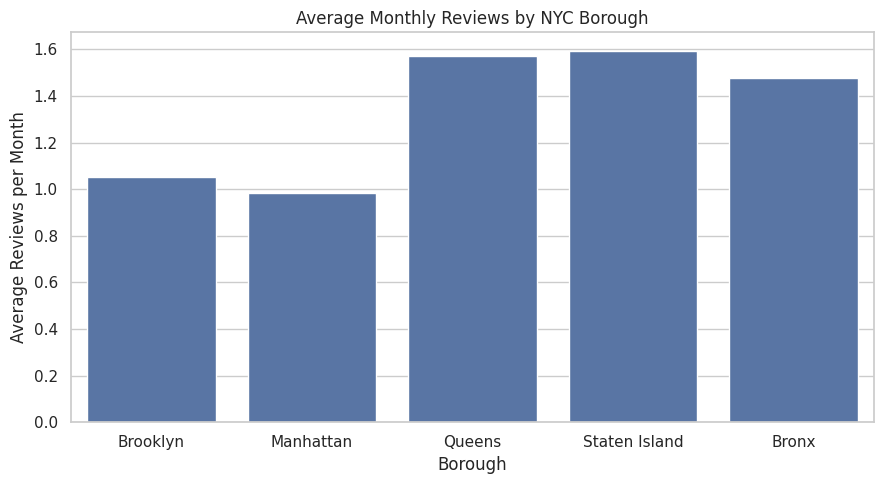

Review rates by room type:


,mean,median,count
room_type,,,
Private room,1.15,0.40,22233
Shared room,1.08,0.42,1150
Entire home/apt,1.05,0.35,25013


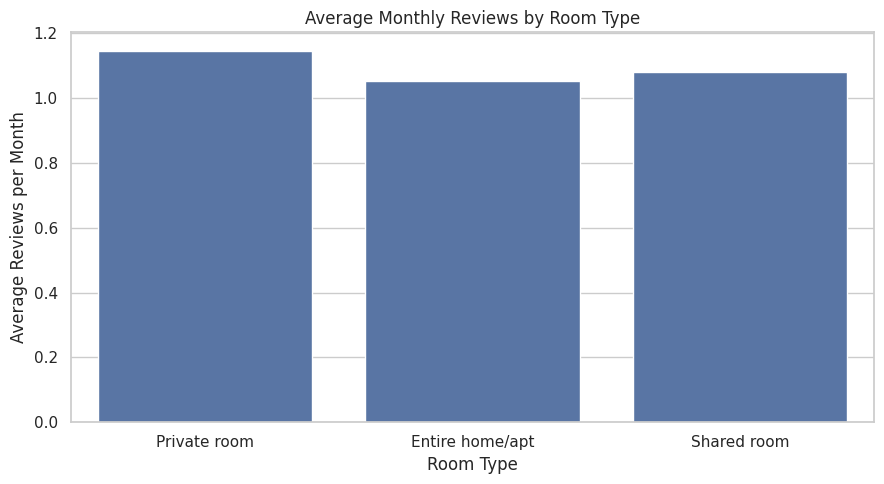

In [14]:
# Popularity analysis: reviews per month
# Missing review rates are excluded from these averages.

reviewed = df.dropna(subset=["reviews_per_month"]).copy()

# Average review rate by borough
borough_reviews = (
    reviewed.groupby("neighbourhood_group")["reviews_per_month"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

print("Review rates by borough:")
display(borough_reviews.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=reviewed,
    x="neighbourhood_group",
    y="reviews_per_month",
    estimator="mean",
    errorbar=None
)
plt.title("Average Monthly Reviews by NYC Borough")
plt.xlabel("Borough")
plt.ylabel("Average Reviews per Month")
plt.tight_layout()
plt.show()

# Average review rate by room type
room_reviews = (
    reviewed.groupby("room_type")["reviews_per_month"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

print("Review rates by room type:")
display(room_reviews.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=reviewed,
    x="room_type",
    y="reviews_per_month",
    estimator="mean",
    errorbar=None
)
plt.title("Average Monthly Reviews by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Average Reviews per Month")
plt.tight_layout()
plt.show()

In [15]:

# Part 7: Data Quality and Missing Values

# 1. Missing values and percentages
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage (%)": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values("Missing Values", ascending=False)

print("Missing Values Summary")
display(missing_summary)

# 2. Listings with zero reviews
zero_reviews = (df["number_of_reviews"] == 0).sum()
print(f"\nListings with zero reviews: {zero_reviews:,}")

# 3. Check whether missing review rates correspond to zero reviews
missing_rate = df["reviews_per_month"].isnull()
print("\nMissing review rate:")
print("Total:", missing_rate.sum())
print("With zero reviews:", (missing_rate & (df["number_of_reviews"] == 0)).sum())
print("With one or more reviews:", (missing_rate & (df["number_of_reviews"] > 0)).sum())

# 4. Check unusual prices and minimum-night values
print("\nListings with zero price:", (df["price"] == 0).sum())
print("Listings above $500:", (df["price"] > 500).sum())
print("Listings with minimum nights above 365:", (df["minimum_nights"] > 365).sum())


Missing Values Summary


,Missing Values,Percentage (%)
last_review,9819,20.29
host_name,21,0.04
name,15,0.03



Listings with zero reviews: 9,819

Missing review rate:
Total: 0
With zero reviews: 0
With one or more reviews: 0

Listings with zero price: 0
Listings above $500: 570
Listings with minimum nights above 365: 0


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use listings with observed monthly review rates
model_df = df.dropna(subset=["reviews_per_month"]).copy()

numeric_features = [
    "price",
    "minimum_nights",
    "latitude",
    "longitude",
    "calculated_host_listings_count",
    "availability_365"
]

categorical_features = [
    "neighbourhood_group",
    "neighbourhood",
    "room_type"
]

features = numeric_features + categorical_features
X = model_df[features]
y = model_df["reviews_per_month"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Prepare numerical and categorical features
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

# Baseline model
baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

# Random Forest model
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# Compare performance
results = pd.DataFrame({
    "Model": ["Median baseline", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, rf_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],
    "R2": [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, rf_pred)
    ]
})

display(results.round(3))


,Model,MAE,RMSE,R2
0,Median baseline,1.031,1.766,-0.223
1,Random Forest,0.794,1.240,0.397


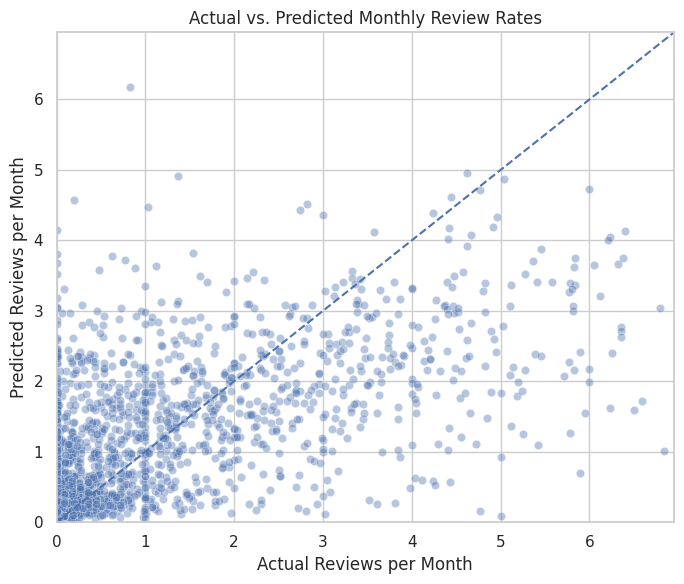

In [17]:
# Actual vs. predicted monthly review rates
plt.figure(figsize=(7, 6))

plot_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": rf_pred
})

sns.scatterplot(
    data=plot_df.sample(
        n=min(2000, len(plot_df)),
        random_state=42
    ),
    x="Actual",
    y="Predicted",
    alpha=0.4
)

limit = plot_df["Actual"].quantile(0.99)

plt.plot([0, limit], [0, limit], "--")
plt.xlim(0, limit)
plt.ylim(0, limit)
plt.title("Actual vs. Predicted Monthly Review Rates")
plt.xlabel("Actual Reviews per Month")
plt.ylabel("Predicted Reviews per Month")
plt.tight_layout()
plt.show()


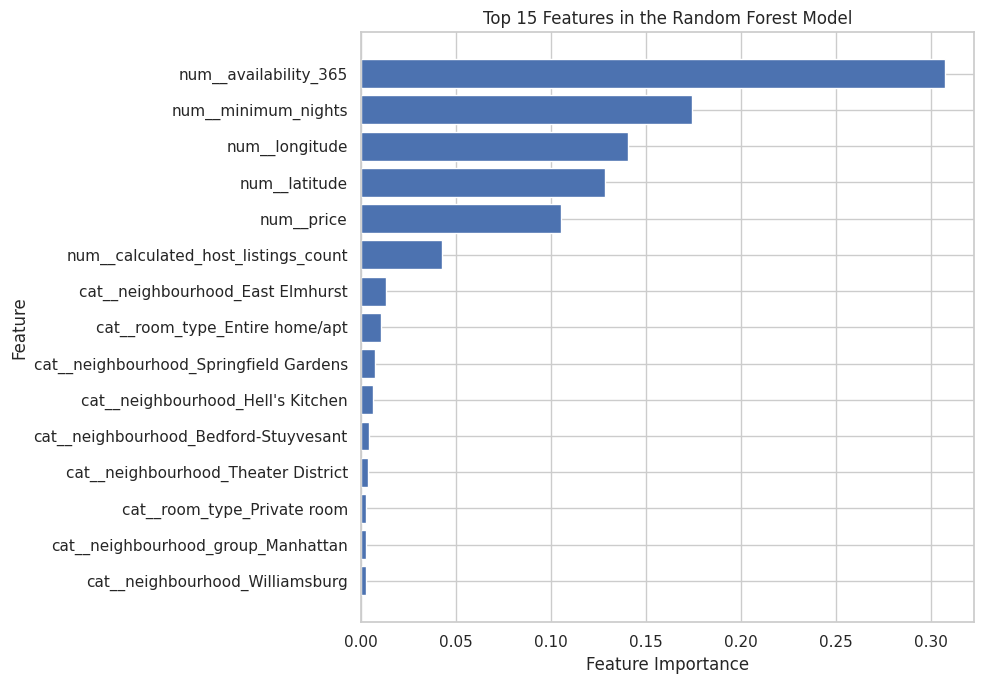

,Feature,Importance
5,num__availability_365,0.3071
1,num__minimum_nights,0.1743
3,num__longitude,0.1403
2,num__latitude,0.1281
0,num__price,0.1051
4,num__calculated_host_listings_count,0.0424
70,cat__neighbourhood_East Elmhurst,0.0133
230,cat__room_type_Entire home/apt,0.0107
192,cat__neighbourhood_Springfield Gardens,0.0075
105,cat__neighbourhood_Hell's Kitchen,0.0063


In [18]:
# Extract feature names after preprocessing
preprocessor_fitted = rf_model.named_steps["preprocessor"]
regressor = rf_model.named_steps["regressor"]

feature_names = preprocessor_fitted.get_feature_names_out()
importances = regressor.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

# Show the top 15 individual features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Features in the Random Forest Model")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(importance_df.head(15).round(4))
